In [ ]:
# Smart Delivery Agent - A* Algorithm

road_map = {
    "Warehouse": {"A": 4, "B": 2},
    "A": {"Warehouse": 4, "C": 5, "Customer": 10},
    "B": {"Warehouse": 2, "C": 3},
    "C": {"A": 5, "B": 3, "Customer": 4},
    "Customer": {"A": 10, "C": 4}
}

# Estimated cost from each place to the customer
heuristic = {
    "Warehouse": 7,
    "A": 4,
    "B": 6,
    "C": 3,
    "Customer": 0
}

start = "Warehouse"
goal = "Customer"

blocked_roads = []

print("Smart Delivery Agent")
print("Start:", start)
print("Destination:", goal)
print("Map is ready!")

Smart Delivery Agent
Start: Warehouse
Destination: Customer
Map is ready!


In [ ]:


def a_star(road_map, heuristic, start, goal, blocked_roads):
    open_list = [(heuristic[start], 0, start, [start])]
    best_cost = {start: 0}
    nodes_explored = 0

    while open_list:
        open_list.sort()
        f_cost, g_cost, current, path = open_list.pop(0)

        if g_cost > best_cost[current]:
            continue

        nodes_explored += 1

        if current == goal:
            return path, g_cost, nodes_explored

        for neighbor, road_cost in road_map[current].items():
            if [current, neighbor] in blocked_roads:
                continue
            if [neighbor, current] in blocked_roads:
                continue

            new_g_cost = g_cost + road_cost

            if neighbor not in best_cost or new_g_cost < best_cost[neighbor]:
                best_cost[neighbor] = new_g_cost
                new_f_cost = new_g_cost + heuristic[neighbor]
                new_path = path + [neighbor]

                open_list.append(
                    (new_f_cost, new_g_cost, neighbor, new_path)
                )

    return None, None, nodes_explored


In [ ]:

# Normal Test - No Blocked Roads

blocked_roads = []

route, total_cost, nodes_explored = a_star(
    road_map, heuristic, start, goal, blocked_roads
)

print("=== Normal Test ===")

if route is not None:
    print("Best route:", " -> ".join(route))
    print("Total delivery cost:", total_cost)
else:
    print("No available route.")

print("Nodes explored:", nodes_explored)


=== Normal Test ===
Best route: Warehouse -> B -> C -> Customer
Total delivery cost: 9
Nodes explored: 5


In [ ]:


# Close the road between B and C
blocked_roads = [["B", "C"]]

route, total_cost, nodes_explored = a_star(
    road_map, heuristic, start, goal, blocked_roads
)

print("=== Closed Road Test ===")
print("Blocked road: B <-> C")

if route is not None:
    print("Alternative route:", " -> ".join(route))
    print("Total delivery cost:", total_cost)
else:
    print("No available route!")

print("Nodes explored:", nodes_explored)



=== Closed Road Test ===
Blocked road: B <-> C
Alternative route: Warehouse -> A -> C -> Customer
Total delivery cost: 13
Nodes explored: 5


In [ ]:

# Close all roads leading to the customer
blocked_roads = [
    ["A", "Customer"],
    ["C", "Customer"]
]

route, total_cost, nodes_explored = a_star(
    road_map, heuristic, start, goal, blocked_roads
)

print("=== No Route Test ===")

if route is not None:
    print("Best route:", " -> ".join(route))
    print("Total delivery cost:", total_cost)
else:
    print("No available route to the customer.")

print("Nodes explored:", nodes_explored)


=== No Route Test ===
No available route to the customer.
Nodes explored: 4


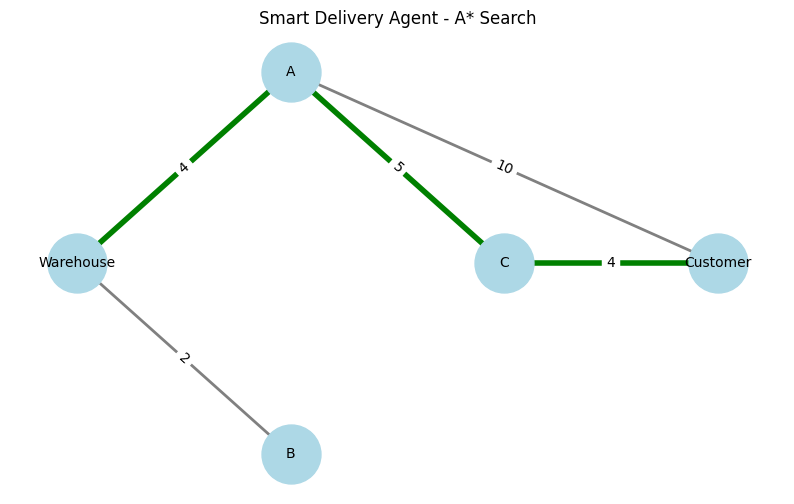

In [ ]:

import networkx as nx
import matplotlib.pyplot as plt

# Close the road between B and C
blocked_roads = [["B", "C"]]

# Run A* again for visualization
route, total_cost, nodes_explored = a_star(
    road_map, heuristic, start, goal, blocked_roads
)

G = nx.Graph()

# Add roads except blocked roads
for place in road_map:
    for neighbor, cost in road_map[place].items():

        if [place, neighbor] in blocked_roads:
            continue

        if [neighbor, place] in blocked_roads:
            continue

        G.add_edge(place, neighbor, weight=cost)

pos = {
    "Warehouse": (0, 0),
    "A": (1, 1),
    "B": (1, -1),
    "C": (2, 0),
    "Customer": (3, 0)
}

route_edges = []

if route is not None:
    for i in range(len(route) - 1):
        route_edges.append((route[i], route[i + 1]))

plt.figure(figsize=(10, 6))

nx.draw_networkx_nodes(
    G, pos, node_size=1800, node_color="lightblue"
)

nx.draw_networkx_edges(
    G, pos, width=2, edge_color="gray"
)

nx.draw_networkx_edges(
    G, pos,
    edgelist=route_edges,
    width=4,
    edge_color="green"
)

nx.draw_networkx_labels(G, pos, font_size=10)

edge_labels = nx.get_edge_attributes(G, "weight")

nx.draw_networkx_edge_labels(
    G, pos, edge_labels=edge_labels
)

plt.title("Smart Delivery Agent - A* Search")
plt.axis("off")
plt.show()



In [ ]:

blocked_roads = [["B", "C"]]

route, total_cost, nodes_explored = a_star(
    road_map, heuristic, start, goal, blocked_roads
)

print("=== Final Test ===")

if route is not None:
    print("Best route:", " -> ".join(route))
    print("Total delivery cost:", total_cost)
else:
    print("No available route.")

print("Nodes explored:", nodes_explored)


=== Final Test ===
Best route: Warehouse -> A -> C -> Customer
Total delivery cost: 13
Nodes explored: 5
